In [1]:
import ler
ler.__version__

'1.0.2'

In [2]:
from ler import LeR

jyp = LeR(
    npool = 4,
)

Extracting interpolator data from package to interpolator_json.

Initializing LeR class...


Initializing LensGalaxyParameterDistribution class...


Initializing OpticalDepth class

comoving_distance interpolator will be loaded from ./interpolator_json/comoving_distance/comoving_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
differential_comoving_volume interpolator will be loaded from ./interpolator_json/differential_comoving_volume/differential_comoving_volume_0.json
using ler available velocity dispersion function : velocity_dispersion_ewoud
velocity_dispersion_ewoud interpolator will be loaded from ./interpolator_json/velocity_dispersion/velocity_dispersion_ewoud_0.json
using ler available axis_ratio function : rayleigh
rayleigh interpolator

## Unlensed

In [3]:
unlensed_pop = jyp.unlensed_cbc_statistics()

unlensed params will be stored in ./ler_data/unlensed_param.json
removing ./ler_data/unlensed_param.json if it exists
resuming from ./ler_data/unlensed_param.json
Batch no. 1
sampling gw source params...
calculating pdet...
Batch no. 2
sampling gw source params...
calculating pdet...
saving all unlensed parameters in ./ler_data/unlensed_param.json 


In [4]:
unlensed_pop['zs']

array([3.15508276, 1.13552207, 2.87033808, ..., 2.89602855,
       2.24909939, 1.12534882], shape=(100000,))

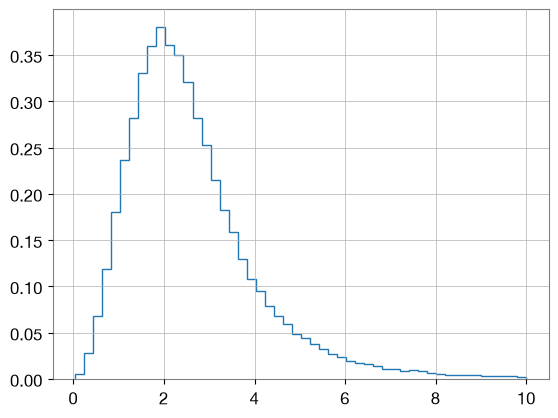

In [13]:
import matplotlib.pyplot as plt

plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0');

In [6]:
unlensed_rate, unlensed_pop_det = jyp.unlensed_rate(
    unlensed_param = unlensed_pop,
)

Using provided unlensed_param dict...
total unlensed rate (yr^-1): 324.4538378287462
number of simulated unlensed detectable events: 352
number of simulated all unlensed events: 100000
storing detectable params in ./ler_data/unlensed_param_detectable.json


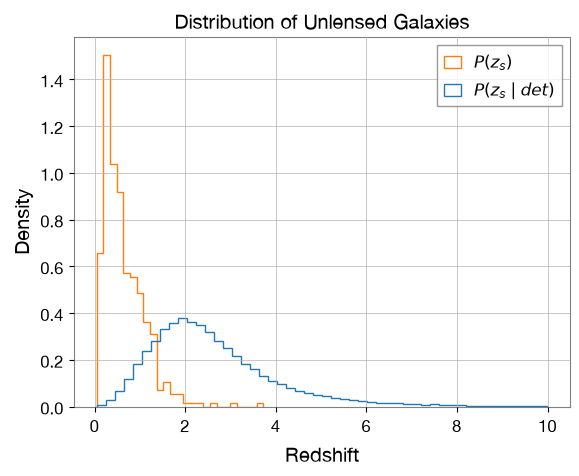

In [ ]:
plt.hist(unlensed_pop_det['zs'], bins=25, density=True, histtype='step', color='C1');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0');
plt.xlabel('Redshift')
plt.ylabel('Density')
plt.title('Distribution of Unlensed Galaxies')
plt.legend([r'$P(z_s)$', '$P(z_s\mid det)$'])
plt.show()

In [9]:
from ler.utils import get_param_from_json   # 아까 저장했던 output json 파일을 불러올 수 있음

unlensed_param_det = get_param_from_json(
    json_file = './ler_data/unlensed_param_detectable.json'
)

In [10]:
unlensed_param_det  # like this

{'zs': array([0.14415277, 0.44892136, 0.78297551, ..., 0.79444081,
        0.32777106, 0.42511661], shape=(352,)),
 'mass_1_source': array([ 9.780924  , 20.67478606, 50.80908478, ..., 54.89776882,
        32.98214064, 34.44394887], shape=(352,)),
 'mass_ratio': array([0.952241  , 0.54227968, 0.90447499, ..., 0.45784639,
        0.52570542, 0.88334303], shape=(352,)),
 'mass_2_source': array([ 9.31379689, 11.21151631, 45.95554625, ..., 25.13474542,
        17.33889011, 30.42582209], shape=(352,)),
 'geocent_time': array([1.26965550e+09, 1.26740346e+09, 1.26724330e+09, ...,
        1.25108035e+09, 1.26150589e+09, 1.25760107e+09],
       shape=(352,)),
 'ra': array([5.04795996, 0.35696732, 0.52227233, ..., 3.80042914,
        2.11797643, 2.79120775], shape=(352,)),
 'dec': array([ 0.21736213,  1.14802887, -1.28793335, ...,  1.04972908,
        -0.04236194,  0.67279895], shape=(352,)),
 'phase': array([2.51745573, 3.82015656, 1.08105787, ..., 4.82741426,
        0.77664956, 4.12892023], sh

## Lensed

In [11]:
lensed_pop = jyp.lensed_cbc_statistics()

lensed params will be stored in ./ler_data/lensed_param.json
removing ./ler_data/lensed_param.json if it exists
resuming from ./ler_data/lensed_param.json
Batch no. 1
sampling lensed params...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
Invalid sample found. Resampling 142 lensed events...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
Invalid sample found. Resampling 1 lensed events...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
calculating pdet...
Batch no. 2
sampling lensed params...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
Invalid sample found. Resampling 131 lensed events...
sampling lens parameters with epl

In [12]:
lensed_pop['time_delays'][0]
# column = images, row = events

array([       0.        , 21336613.80192845,               nan,
                     nan])

In [13]:
# Recover redundant parameters (like theta_E, n_images, mass_1, mass_2, luminosity_distance) for the detectable lensed events
lensed_pop = jyp.recover_redundant_parameters(lensed_pop)
lensed_pop = jyp.produce_effective_params(lensed_pop)

In [14]:
lensed_pop['effective_geocent_time'][0][1]-lensed_pop['effective_geocent_time'][0][0]

np.float64(21336613.80192852)

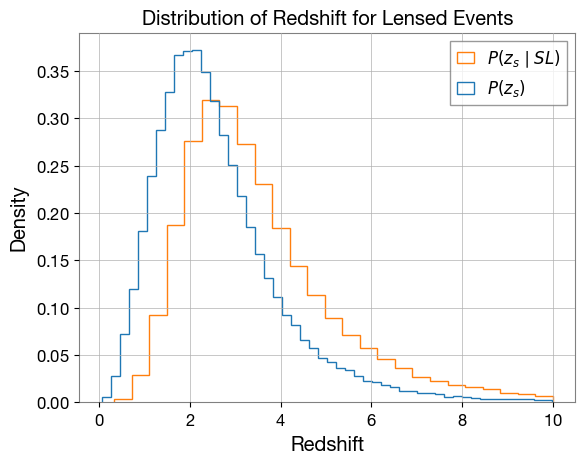

In [15]:
# plot redshift

plt.hist(lensed_pop['zs'], bins=25, density=True, histtype='step', color='C1', label=r'$P(z_s\mid SL)$');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0', label=r'$P(z_s)$');
plt.xlabel('Redshift');
plt.ylabel('Density');
plt.title('Distribution of Redshift for Lensed Events');
plt.legend();
plt.show();

In [16]:
lensed_rate, lensed_pop_det = jyp.lensed_rate(
    lensed_param = lensed_pop,
)

Using provided lensed_param dict...
total lensed rate (yr^-1): 0.18341020867586943
number of simulated lensed detectable events: 164
number of simulated all lensed events: 100000
storing detectable params in ./ler_data/lensed_param_detectable.json


In [17]:
jyp.rate_ratio()

unlensed_rate: 324.4538378287462
lensed_rate: 0.18341020867586943
ratio: 1769.0064264750674


1769.0064264750674

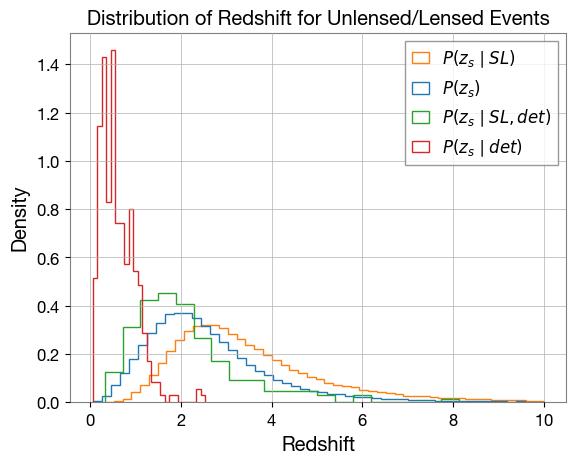

In [18]:
plt.hist(lensed_pop['zs'], bins=50, density=True, histtype='step', color='C1', label=r'$P(z_s\mid SL)$');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0', label=r'$P(z_s)$');
plt.hist(lensed_pop_det['zs'], bins=20, density=True, histtype='step', color='C2', label=r'$P(z_s\mid SL, det)$');
plt.hist(unlensed_pop_det['zs'], bins=25, density=True, histtype='step', color='C3', label=r'$P(z_s\mid det)$');
plt.xlabel('Redshift');
plt.ylabel('Density');
plt.title('Distribution of Redshift for Unlensed/Lensed Events');
plt.legend();
plt.show();

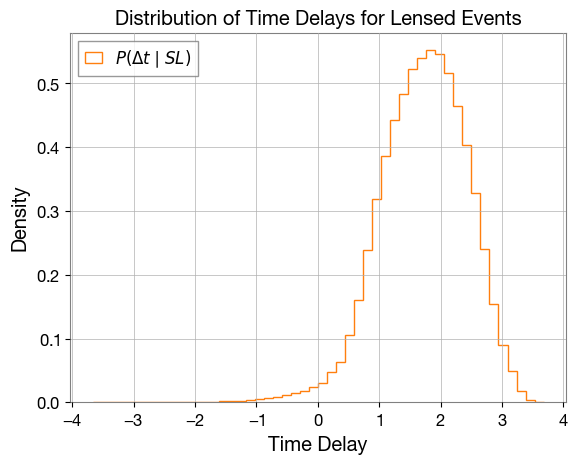

In [21]:
import numpy as np

# plot time delay
# covert secs to days
dt = (lensed_pop['effective_geocent_time'][:,1]-lensed_pop['effective_geocent_time'][:,0])/(24*3600)
log10_dt = np.log10(dt)
plt.hist(log10_dt, bins=50, density=True, histtype='step', color='C1', label=r'$P(\Delta t\mid SL)$');
plt.xlabel('Time Delay');
plt.ylabel('Density');
plt.title('Distribution of Time Delays for Lensed Events');
plt.legend();
plt.show();